# Clasificación de ingresos con redes neuronales

Se utilizan los archivos originales de `data/raw/` mediante `load_dataset()` y se retoman las decisiones de `01_data_exploration.ipynb` para comparar un perceptrón y dos MLP sobre Adult. La clase positiva es **>50K**; precision, recall y F1 se calculan para ella. No se eliminan registros atípicos ni se ajustan hiperparámetros con los conjuntos de prueba.

## 1. Configuración y carga

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Perceptron
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.dataset import load_dataset

SEED = 42
sns.set_theme(style="whitegrid", palette="pastel", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 150
colors = sns.color_palette("pastel", 3)

In [2]:
data = load_dataset()

assert data.shape == (48_842, 15)
education_pairs = data[["education", "education-num"]].drop_duplicates()
assert education_pairs["education"].is_unique
assert education_pairs["education-num"].is_unique
assert not education_pairs.isna().any().any()

income = data["income"].str.strip().str.rstrip(".")
assert set(income.unique()) == {"<=50K", ">50K"}
y = income.map({"<=50K": 0, ">50K": 1})
X = data.drop(columns=["income", "education", "fnlwgt"])
categorical_columns = X.select_dtypes(exclude="number").columns.tolist()
X[categorical_columns] = X[categorical_columns].replace("?", np.nan)
assert not X.select_dtypes(include="number").isna().any().any()

print(f"Registros: {len(data):,}; correspondencias educativas únicas: {len(education_pairs)}")
print(f"Clase >50K: {y.mean():.2%}; accuracy de predecir siempre ≤50K: {1 - y.mean():.2%}")

Registros: 48,842; correspondencias educativas únicas: 16
Clase >50K: 23.93%; accuracy de predecir siempre ≤50K: 76.07%


## 2. Preprocesamiento y arquitecturas

Se conserva `education-num` porque su correspondencia con `education` es uno a uno. Se descarta `fnlwgt` por representar un peso censal y por su baja asociación lineal observada en la exploración. Se mantienen las 48.842 filas.

Cada partición utiliza un preprocesador nuevo: faltantes categóricos como `Unknown`, one-hot encoding, `log1p` en las variables de capital y estandarización de todas las variables numéricas. Las categorías y los parámetros del escalado se aprenden exclusivamente del entrenamiento; las categorías nuevas en prueba se ignoran.

El perceptrón tiene una salida con umbral y bias. Las MLP usan ReLU, bias en todas sus capas entrenables y una salida logística binaria. La primera tiene una capa de **n** neuronas, donde **n** se obtiene de la matriz transformada de cada entrenamiento; la segunda tiene capas de **2 y 2** neuronas.

In [3]:
capital_columns = ["capital-gain", "capital-loss"]
other_numeric_columns = ["age", "education-num", "hours-per-week"]


def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("transform", ColumnTransformer([
            ("capital", FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
             capital_columns),
            ("other", "passthrough", other_numeric_columns),
        ])),
        ("scale", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, capital_columns + other_numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ])


def make_models(n_features):
    mlp_parameters = dict(
        activation="relu", solver="adam", max_iter=400,
        random_state=SEED, early_stopping=False, n_iter_no_change=20,
    )
    return {
        "Perceptrón": Perceptron(fit_intercept=True, max_iter=1000, random_state=SEED),
        "MLP (n)": MLPClassifier(hidden_layer_sizes=(n_features,), **mlp_parameters),
        "MLP (2, 2)": MLPClassifier(hidden_layer_sizes=(2, 2), **mlp_parameters),
    }

## 3. Experimentación

Las particiones 70/30, 80/20 y 90/10 son estratificadas y usan semilla 42. Dentro de cada partición, las tres arquitecturas reciben exactamente las mismas filas y características transformadas. Se mantienen los valores predeterminados restantes, sin búsqueda de hiperparámetros ni ponderación de clases. Por el desbalanceo, la comparación prioriza F1 y revisa conjuntamente precision y recall de >50K; accuracy sirve como complemento.

Las MLP detienen el entrenamiento cuando la pérdida deja de mejorar según su tolerancia, con un máximo de 400 épocas. No se utiliza el conjunto de prueba para detenerlas. Se limita el paralelismo numérico para hacer reproducible la ejecución.

In [4]:
records = []
experiments = {}

with threadpool_limits(limits=1):
    for split, test_size in [("70/30", 0.30), ("80/20", 0.20), ("90/10", 0.10)]:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, stratify=y, random_state=SEED,
        )
        preprocessor = make_preprocessor()
        train_inputs = preprocessor.fit_transform(X_train)
        test_inputs = preprocessor.transform(X_test)
        n_features = train_inputs.shape[1]
        assert train_inputs.shape[0] + test_inputs.shape[0] == 48_842
        assert np.isfinite(train_inputs).all() and np.isfinite(test_inputs).all()
        print(
            f"{split}: entrenamiento={len(y_train)}, prueba={len(y_test)}, "
            f"n={n_features}, >50K en prueba={y_test.mean():.2%}"
        )

        for architecture, model in make_models(n_features).items():
            model.fit(train_inputs, y_train)
            predictions = model.predict(test_inputs)
            records.append({
                "split": split,
                "architecture": architecture,
                "accuracy": accuracy_score(y_test, predictions),
                "precision": precision_score(y_test, predictions, zero_division=0),
                "recall": recall_score(y_test, predictions, zero_division=0),
                "f1": f1_score(y_test, predictions, zero_division=0),
            })
            experiments[(split, architecture)] = {
                "model": model,
                "confusion": confusion_matrix(y_test, predictions, labels=[0, 1]),
            }
            if isinstance(model, MLPClassifier):
                assert model.out_activation_ == "logistic"
                assert model.n_outputs_ == 1
                assert all(bias.size > 0 for bias in model.intercepts_)
                print(f"  {architecture}: {model.n_iter_} épocas")

results = pd.DataFrame(records)
metric_columns = ["accuracy", "precision", "recall", "f1"]
architecture_order = ["Perceptrón", "MLP (n)", "MLP (2, 2)"]
split_order = ["70/30", "80/20", "90/10"]

70/30: entrenamiento=34189, prueba=14653, n=91, >50K en prueba=23.93%


/home/valkyrie/Documents/PUJ/sem8/IA/proyecto3/neural-income-classifier/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (400) reached and the optimization hasn't converged yet.
  warnings.warn(


  MLP (n): 400 épocas


  MLP (2, 2): 109 épocas
80/20: entrenamiento=39073, prueba=9769, n=91, >50K en prueba=23.93%


/home/valkyrie/Documents/PUJ/sem8/IA/proyecto3/neural-income-classifier/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (400) reached and the optimization hasn't converged yet.
  warnings.warn(


  MLP (n): 400 épocas


  MLP (2, 2): 93 épocas
90/10: entrenamiento=43957, prueba=4885, n=91, >50K en prueba=23.93%


/home/valkyrie/Documents/PUJ/sem8/IA/proyecto3/neural-income-classifier/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (400) reached and the optimization hasn't converged yet.
  warnings.warn(


  MLP (n): 400 épocas


  MLP (2, 2): 133 épocas


## 4. Resultados

### Tabla comparativa de métricas

In [5]:
display(
    results.set_index(["split", "architecture"])[metric_columns]
    .style.format("{:.4f}")
    .highlight_max(axis=0, color="#D5E8D4")
    .set_caption("Métricas en prueba; precision, recall y F1 para >50K")
)

La MLP de una capa utiliza **91 entradas y 91 neuronas ocultas** en las tres particiones. Obtiene el mejor F1 en 80/20 (0,6685) y 90/10 (0,6820), mientras que la MLP de 2+2 gana en 70/30 (0,6633). En 90/10 ambas MLP alcanzan 85,57 % de accuracy, pero la primera recupera más casos >50K: 64,67 % frente a 60,22 %. Para equilibrar precision y recall de la clase minoritaria, la MLP de 91 neuronas resulta la mejor candidata en estos experimentos.

### Rendimiento por arquitectura y partición

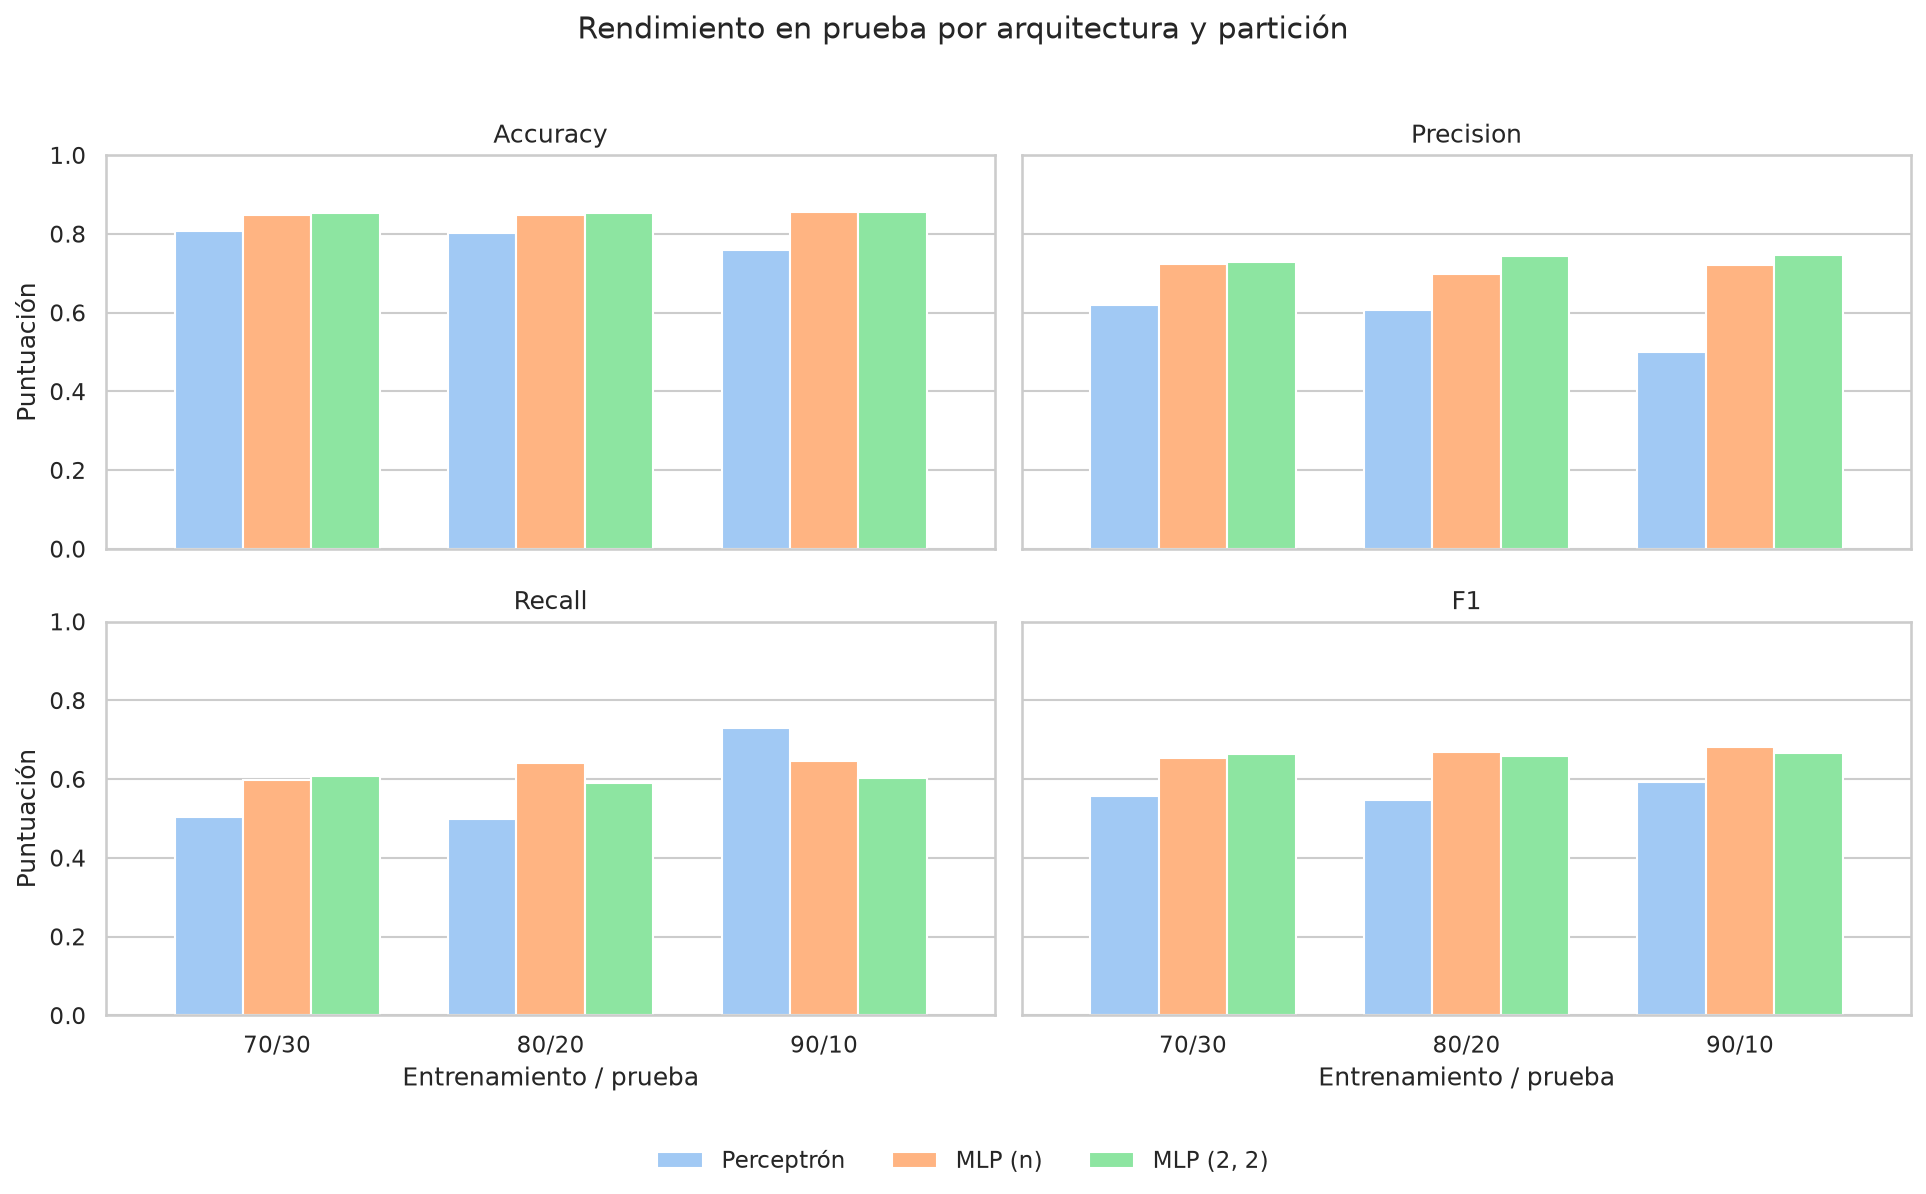

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)
for metric, ax in zip(metric_columns, axes.flat):
    values = results.pivot(index="split", columns="architecture", values=metric)
    values = values.reindex(index=split_order, columns=architecture_order)
    values.plot.bar(ax=ax, color=colors, rot=0, width=0.75, legend=False)
    ax.set_title(metric.upper() if metric == "f1" else metric.capitalize())
    ax.set_xlabel("Entrenamiento / prueba")
    ax.set_ylabel("Puntuación")
    ax.set_ylim(0, 1)
    ax.grid(axis="x", visible=False)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Rendimiento en prueba por arquitectura y partición")
fig.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.show()

Las MLP superan al perceptrón en F1 en las tres particiones. La red de 2+2 mantiene mayor precision, mientras que la de 91 neuronas ofrece mayor recall en 80/20 y 90/10. El perceptrón sube a 72,97 % de recall en 90/10, pero su precision cae a 49,91 % y su accuracy a 76,01 %, prácticamente el nivel de predecir siempre la clase mayoritaria. Por eso, su mayor recall aislado no justifica elegirlo. Aumentar el entrenamiento favorece el F1 de la MLP de 91 neuronas (0,6540 → 0,6685 → 0,6820), aunque no produce mejoras uniformes en todas las arquitecturas.

### Matrices de confusión

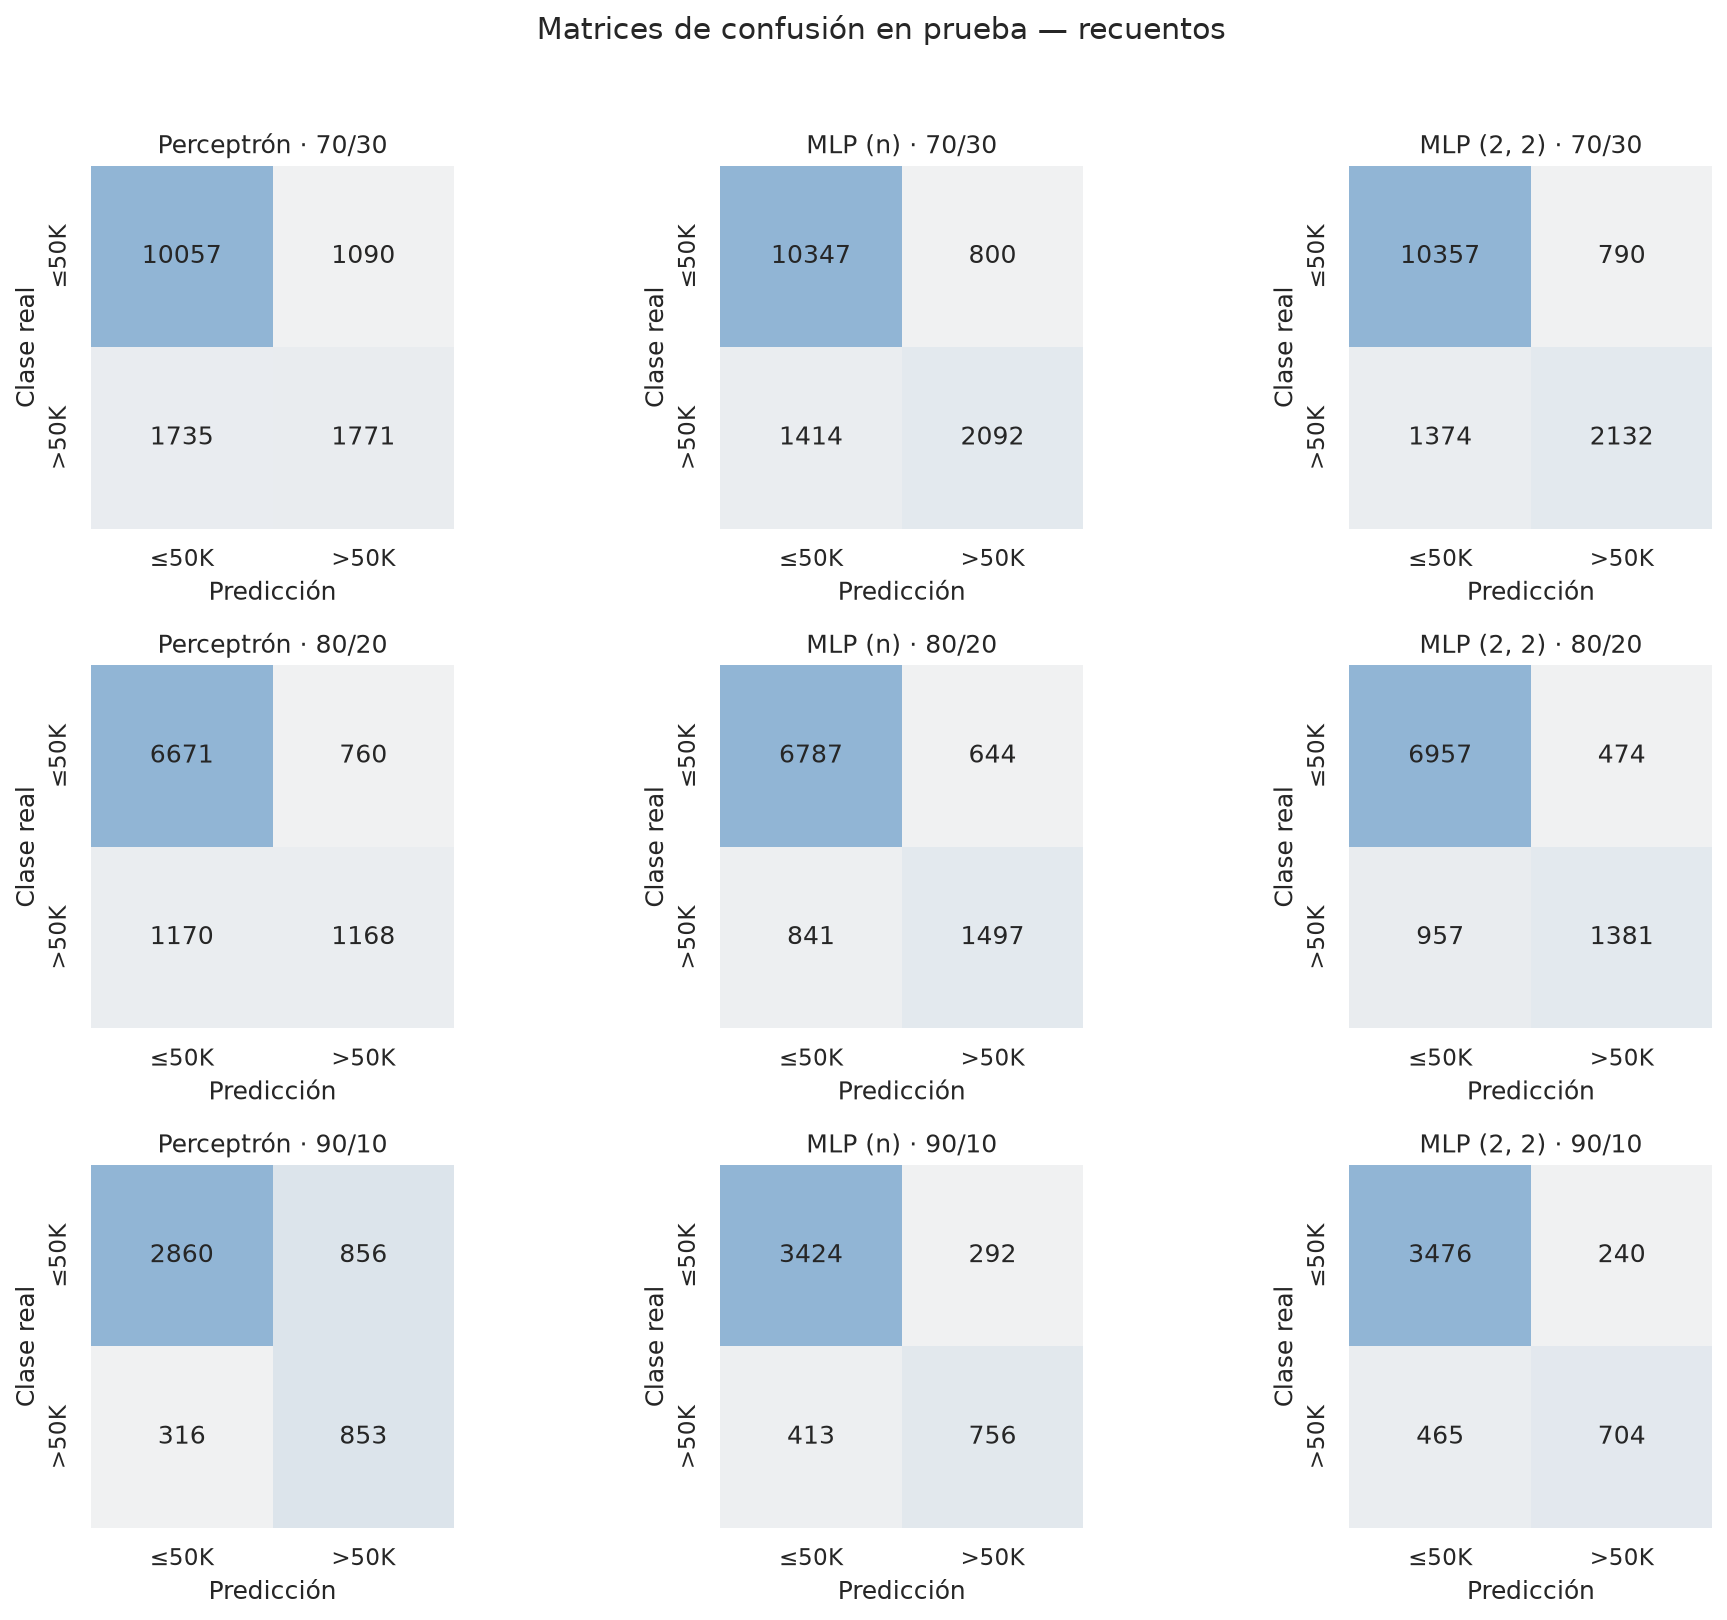

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for row, split in enumerate(split_order):
    for column, architecture in enumerate(architecture_order):
        ax = axes[row, column]
        matrix = experiments[(split, architecture)]["confusion"]
        sns.heatmap(
            matrix, annot=True, fmt="d", cmap=sns.light_palette("#91B5D5", as_cmap=True),
            cbar=False, square=True, ax=ax,
            xticklabels=["≤50K", ">50K"], yticklabels=["≤50K", ">50K"],
        )
        ax.set_title(f"{architecture} · {split}")
        ax.set_xlabel("Predicción")
        ax.set_ylabel("Clase real")
fig.suptitle("Matrices de confusión en prueba — recuentos")
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

En 80/20, la MLP de 91 neuronas deja sin detectar 841 personas >50K, frente a 957 de la red de 2+2 y 1.170 del perceptrón. A cambio, genera 644 falsos positivos, frente a 474 de la MLP pequeña. Esto concreta el compromiso del problema: detectar más ingresos altos implica aceptar más clasificaciones positivas erróneas. Elegiríamos la primera por su mejor F1; si se priorizara reducir falsos positivos, la red de 2+2 sería preferible. Los recuentos entre particiones tienen distintos tamaños de prueba y deben contrastarse con precision y recall, no compararse directamente.

### Pérdida de las MLP en la partición 80/20

MLP (n): pérdida inicial=0.3713, final=0.2410; épocas=400
MLP (2, 2): pérdida inicial=0.7427, final=0.3107; épocas=93


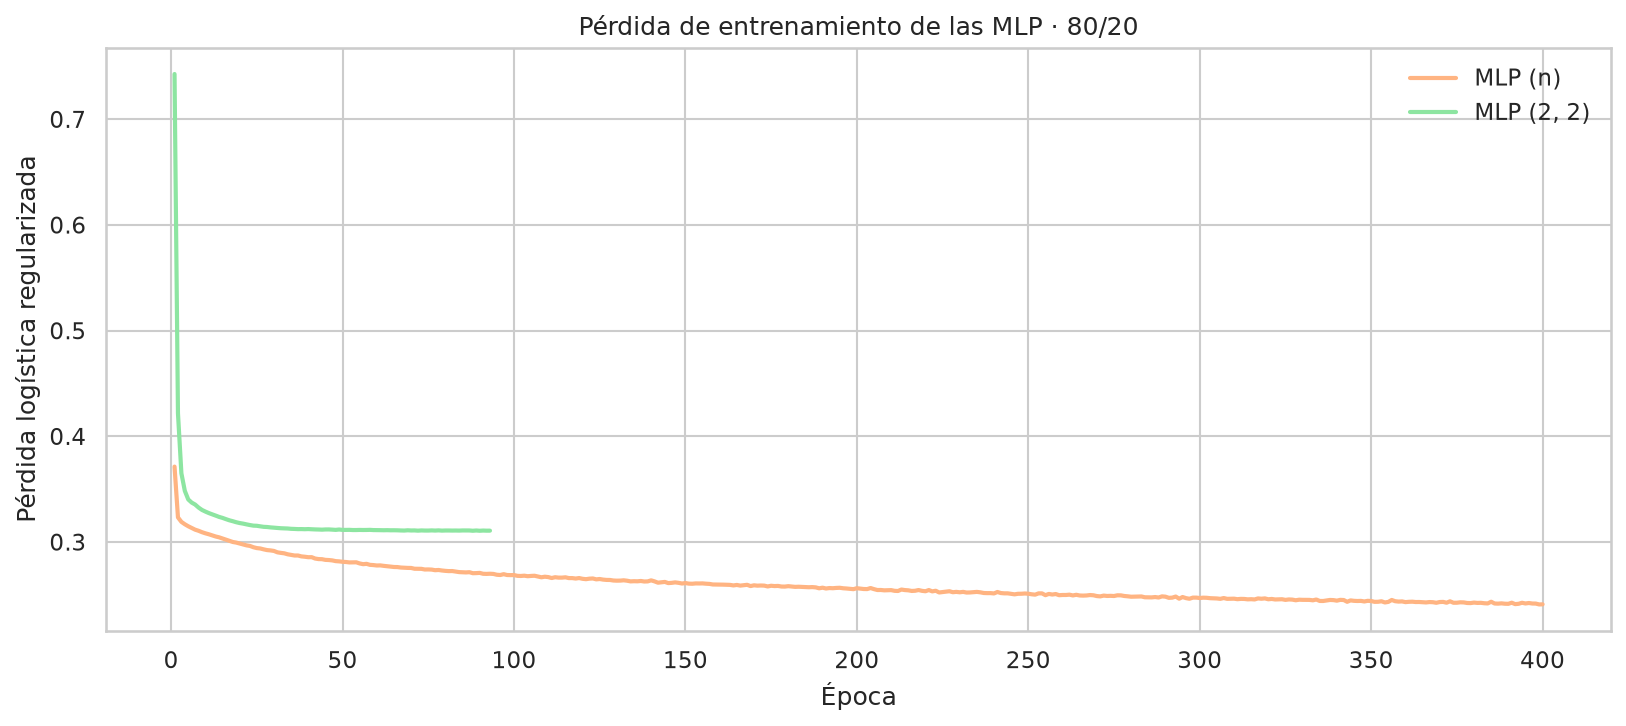

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
for architecture, color in zip(architecture_order[1:], colors[1:]):
    model = experiments[("80/20", architecture)]["model"]
    ax.plot(range(1, len(model.loss_curve_) + 1), model.loss_curve_,
            label=architecture, color=color, linewidth=2)
    print(
        f"{architecture}: pérdida inicial={model.loss_curve_[0]:.4f}, "
        f"final={model.loss_curve_[-1]:.4f}; épocas={model.n_iter_}"
    )
ax.set(title="Pérdida de entrenamiento de las MLP · 80/20",
       xlabel="Época", ylabel="Pérdida logística regularizada")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

En 80/20, la pérdida de la MLP de 91 neuronas baja de 0,3713 a 0,2410 durante 400 épocas; la de 2+2 baja de 0,7427 a 0,3107 y se detiene en 93 épocas al dejar de mejorar según la tolerancia configurada. La red más amplia logra menor pérdida de entrenamiento y mayor F1 en esta partición, pero alcanza el límite de épocas sin converger, como también ocurre en 70/30 y 90/10. Su resultado corresponde a ese presupuesto de entrenamiento. Estas curvas solo muestran entrenamiento: no permiten confirmar ni descartar sobreajuste. La decisión se apoya también en las métricas de prueba.

## 5. Comparación final

El **perceptrón** obtiene el menor F1 en todas las particiones (0,5476–0,5928) y cambia considerablemente su equilibrio entre precision y recall. La **MLP de 2+2** ofrece una alternativa pequeña, con la mayor precision en las tres particiones (0,7296–0,7458) y el mejor F1 en 70/30. La **MLP de 91 neuronas** presenta el mejor equilibrio global al priorizar F1: gana en 80/20 y 90/10, con un F1 medio descriptivo de 0,6681 frente a 0,6628 de la red pequeña.

La mejor configuración observada es **MLP de 91 neuronas, 90/10**: accuracy **85,57 %**, precision **72,14 %**, recall **64,67 %** y F1 **0,6820**. Aun así, omite 413 de los 1.169 positivos del conjunto de prueba, por lo que el desbalanceo sigue siendo relevante.

El reparto 90/10 produce el mayor F1 de cada arquitectura, pero también reduce la prueba a 4.885 personas. Como cambian tanto el tamaño del entrenamiento como las filas evaluadas, una sola semilla no permite atribuir toda la diferencia a disponer de más datos ni asegurar que 90/10 sea siempre superior. La elección de la MLP amplia queda limitada por su falta de convergencia a las 400 épocas; estos resultados comparan las configuraciones ejecutadas, sin afirmar que sean óptimas.